In [1]:
#Setup Cell

import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB


ROOT = Path.cwd().parent
DATA = ROOT / "all_datasets"
RESULTS = ROOT / "results" / "lab07"

RESULTS.mkdir(parents=True, exist_ok=True)

CLASSES = ["negative", "neutral", "positive"]

In [2]:
#Question 1

tweets = pd.read_csv(
    DATA / "lab07-Tweets.csv",
    dtype={"tweet_id": str}
)[["tweet_id", "text", "airline_sentiment", "airline"]]


def clean(text):
    text = re.sub(r"https?://\S+|www\.\S+", " URL ", text)
    text = re.sub(r"@\w+", " USER ", text)
    return " ".join(text.lower().split())


print("Raw tweets:", len(tweets), "| exact duplicate texts:", int(tweets.text.duplicated().sum()))

tweets["model_text"] = tweets.text.map(clean)

print("Duplicates after normalisation:", int(tweets.model_text.duplicated().sum()))

tweets = tweets.drop_duplicates("model_text").reset_index(drop=True)

print("Tweets kept:", len(tweets))

display(
    tweets.airline_sentiment
    .value_counts(normalize=True)
    .rename("share")
    .round(3)
    .to_frame()
)

Raw tweets: 14640 | exact duplicate texts: 213
Duplicates after normalisation: 355
Tweets kept: 14285


,share
airline_sentiment,
negative,0.635
neutral,0.209
positive,0.156


In [3]:
#Question 2

train, rest = train_test_split(
    tweets.index,
    test_size=0.30,
    random_state=42,
    stratify=tweets.airline_sentiment
)

val, test = train_test_split(
    rest,
    test_size=0.50,
    random_state=42,
    stratify=tweets.airline_sentiment[rest]
)

tweets["split"] = "train"
tweets.loc[val, "split"] = "validation"
tweets.loc[test, "split"] = "test"

tweets[["tweet_id", "airline_sentiment", "split"]].to_csv(
    RESULTS / "split.csv",
    index=False
)

display(
    pd.crosstab(
        tweets.split,
        tweets.airline_sentiment,
        margins=True
    )
)

airline_sentiment,negative,neutral,positive,All
split,,,,
test,1361,447,335,2143
train,6348,2087,1564,9999
validation,1360,447,336,2143
All,9069,2981,2235,14285


In [4]:
#Question 3

def vectorizer(ngram_range):
    return CountVectorizer(
        stop_words="english",
        min_df=2,
        max_features=20_000,
        ngram_range=ngram_range
    )


for ngram_range in [(1, 1), (1, 2)]:
    vocabulary = vectorizer(ngram_range).fit(
        tweets.model_text[train]
    ).vocabulary_

    print(f"ngram_range={ngram_range}: {len(vocabulary):,} features")

ngram_range=(1, 1): 4,671 features
ngram_range=(1, 2): 11,850 features


In [6]:
#Question 4

majority = tweets.airline_sentiment[train].mode()[0]
y_val = tweets.airline_sentiment[val]

majority_f1 = f1_score(
    y_val,
    [majority] * len(val),
    average="macro"
)

print(
    f"Majority class: {majority} | "
    f"validation accuracy {(y_val == majority).mean():.3f} | "
    f"validation macro F1 {majority_f1:.3f}"
)


Majority class: negative | validation accuracy 0.635 | validation macro F1 0.259


In [7]:
#Question 5

majority = tweets.airline_sentiment[train].mode()[0]
y_val = tweets.airline_sentiment[val]

majority_f1 = f1_score(
    y_val,
    [majority] * len(val),
    average="macro"
)

print(
    f"Majority class: {majority} | "
    f"validation accuracy {(y_val == majority).mean():.3f} | "
    f"validation macro F1 {majority_f1:.3f}"
)

Majority class: negative | validation accuracy 0.635 | validation macro F1 0.259


,model,accuracy,macro_precision,macro_recall,macro_f1
0,Majority baseline,0.6351,0.2117,0.3333,0.2589
1,Multinomial NB,0.7788,0.7355,0.6732,0.6967


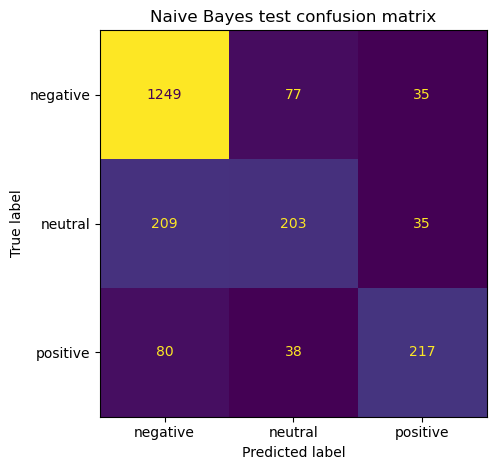

In [11]:
#Question 6

best_ngram = (1, 2)
best_alpha = 1.0

features = vectorizer(best_ngram).fit(tweets.model_text[train])

model = MultinomialNB(alpha=best_alpha).fit(
    features.transform(tweets.model_text[train]),
    tweets.airline_sentiment[train]
)

X_test = features.transform(tweets.model_text[test])

test_set = tweets.loc[test].assign(
    prediction=model.predict(X_test),
    confidence=model.predict_proba(X_test).max(axis=1)
)

test_set.to_csv(RESULTS / "test_predictions.csv", index=False)

y_test = test_set.airline_sentiment


def metric_row(name, prediction):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test,
        prediction,
        average="macro",
        zero_division=0
    )

    return {
        "model": name,
        "accuracy": accuracy_score(y_test, prediction),
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": f1
    }


metrics = pd.DataFrame([
    metric_row("Majority baseline", [majority] * len(test)),
    metric_row("Multinomial NB", test_set.prediction)
])

metrics.to_csv(RESULTS / "metrics.csv", index=False)

display(metrics.round(4))

matrix = confusion_matrix(
    y_test,
    test_set.prediction,
    labels=CLASSES
)

pd.DataFrame(
    matrix,
    index=CLASSES,
    columns=CLASSES
).to_csv(RESULTS / "confusion_matrix.csv")

ConfusionMatrixDisplay(
    matrix,
    display_labels=CLASSES
).plot(colorbar=False)

plt.title("Naive Bayes test confusion matrix")
plt.tight_layout()
plt.savefig(RESULTS / "confusion_matrix.png", dpi=160)